calling GenPaths.py from: .../daaps/pythonModelling/DAAPS_TOOLKIT/GenPaths.py
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/FittingTools
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel
global path variables:
	 PROJECT_PATH =.../.../vera/daaps/pythonModelling/DAAPS_TOOLKIT
	 OPTICS_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA
	 LITERATURE_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/literatureDATA
	 VERA_DATA_PATH =.../.../projects/vera/daaps/veraData
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'printMembers']


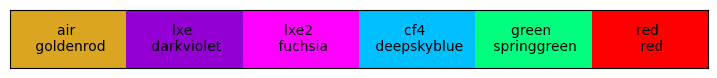

In [1]:
# same as v1 of the notebook, but it uses the actuall module instead of anything defined in here
import numpy as np

import sys
sys.path.append('..')
from DAAPS_TOOLKIT.GenPaths import *

import PDEModel.MathEquations as ME
from PDEModel.OpticsDataLoader import *
import PDEModel.PDEStyle as MS
from PDEModel.PhotonInfo import * # this calls DataLoader when defining init
from PNJunction import * 

import TemperatureCorrections as TC
from TemperatureCorrections import *

# import TemperatureCorrections as TC

MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like
ms.SetMPLcolors()

rad2deg = 180/np.pi

---
#### Blatt Bardeen Hall equation (BDH) 

$$ \alpha(E_\gamma) \propto (E_\gamma - E_g - E_{ph})^2 (1 - E_{ph}/(E_\gamma - E_g)) $$

$$\alpha(E_\gamma) = A(E_\gamma - E_g - E_{ph})^n$$



---
#### DM paper - modified BDH equation

$$ \alpha(E_\gamma) = \sigma_{PE}(T) \rho_{Si} = \sum_{i,j=1,2} C_i A_j \bigg[\frac{(E_\gamma - E_{g,j}(T) - E_{p,i})^2}{e^{E_{p,i}/kT} - 1} +  \frac{(E_\gamma - E_{g,j}(T) + E_{p,i})^2}{1 - e^{-E_{p,i}/kT}} \bigg] + A_d \sqrt{E_\gamma - E_{gd}(T)} $$

$$ \text{abs = indirect1((absorpPhonon1 + emitPhonon1) + (absorpPhonon2 + emitPhonon2)) + indirect2(...) + direct}$$

$$ E_g(T) = E_g(0) - \frac{\beta T^2}{T + \gamma} $$

$$C_i \text{- electron-phonon coupling constant}$$
$$ C_{TA} = 5.5 $$
$$ C_{TO} = 4.0 $$

4.3048785964912275


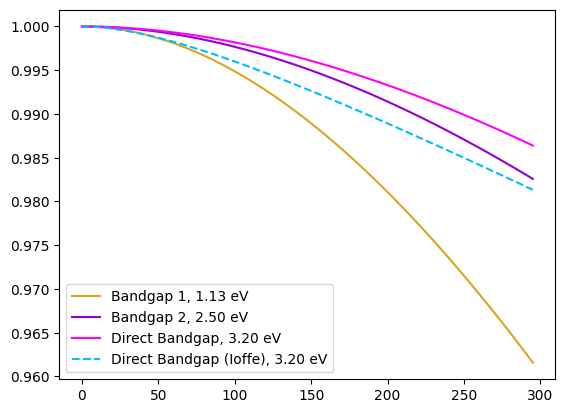

In [2]:
temps = np.arange(0, 300, 5)
Eg1 = TC.Fbandgap(Eg0=Eg_01, T=temps)
Eg2 = TC.Fbandgap(Eg0=Eg_02, T=temps)
Egd = TC.Fbandgap(Eg0=Egd_0, T=temps)
Egd_ioffe = TC.Fbandgap(Eg0=4.34, T=temps, beta=3.91e-4, gamma=125)

plt.plot(temps, Eg1/Eg_01, label=f'Bandgap 1, {Eg_01:0.2f} eV')
plt.plot(temps, Eg2/Eg_02, label=f'Bandgap 2, {Eg_02:0.2f} eV')
plt.plot(temps, Egd/Egd_0, label=f'Direct Bandgap, {Egd_0:0.2f} eV')
plt.plot(temps, Egd_ioffe/4.34, linestyle = "--", label=f'Direct Bandgap (Ioffe), {Egd_0:0.2f} eV')

plt.legend()

print(TC.Fbandgap(Eg0=4.34, T=160, beta=3.91e-4, gamma=125))

ephoton: 1273.301737756714
g1: 0.0
g2: 0.0
direct: 0.0
full: 0.0


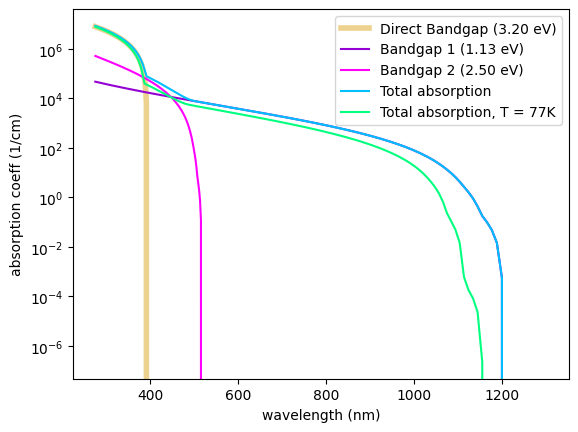

In [3]:
import numpy as np
hc = 1240 # eV nm
ephoton = np.arange(hc/1300, 4.5, 0.01)

Trt = 300
Tln2 = 77

alphaCoeff, g1ta, g1to, g2ta, g2to, direct, _ = TC.alpha(ephoton, Trt, includeDirect=True)

# print(alphaCoeff - (g1ta + g1to + g2ta + g2to + direct))
print("ephoton:", (hc/ephoton)[2])
print("g1:", (g1ta + g1to)[2])
print("g2:", (g2ta + g2to)[2])
print("direct:", direct[2])
print("full:", alphaCoeff[2])

alphaLN2, *_ = TC.alpha(ephoton, Tln2, includeDirect=True)

plt.semilogy(hc/ephoton, (direct), linewidth=4, alpha=0.5, label=f'Direct Bandgap ({Egd_0:0.2f} eV)')


plt.semilogy(hc/ephoton, (g1ta + g1to), label=f'Bandgap 1 ({Eg_01:0.2f} eV)')
# plt.semilogy(hc/ephoton, (g1ta), linestyle = "--", label='gap 1, TA')
# plt.semilogy(hc/ephoton, (g1to), linestyle = "--", label='gap1, TO')

plt.semilogy(hc/ephoton, (g2to + g2ta), label=f'Bandgap 2 ({Eg_02:0.2f} eV)')
# plt.semilogy(hc/ephoton, (g2ta), linestyle = "--", label='gap 2, TA')
# plt.semilogy(hc/ephoton, (g2to), linestyle = "--", label='gap 2, TO')
plt.semilogy(hc/ephoton, alphaCoeff, label='Total absorption')

# plt.semilogy(hc/ephoton, (alphaCoeff - (g1ta + g1to + g2ta + g2to + direct)), label=f'Total absorption, SUM')

plt.semilogy(hc/ephoton, alphaLN2, label=f'Total absorption, T = {Tln2}K')

# min_index = np.argmin(alphaCoeff)
# min_ephoton = ephoton[min_index]
# print(min_ephoton)
# print(Fbandgap(Eg0=Eg_02, T=Trt))


plt.ylabel("absorption coeff (1/cm)")
plt.xlabel("wavelength (nm)")

plt.legend()

In [4]:
import pandas as pd
# Load the data into a DataFrame
data = "dmpaper_supplements/pexsec_experimental_results.txt"
df = pd.read_csv(data, sep='\t')

# Print the headers
names = df.columns
print(names)
colT = names[0]
colEph = names[1]
colSigma = names[4]
print("temps:", df[colT].unique())
print("max Eph:", df[colEph].max())
dfRT = df[(df[colT] > 50) & (df[colT] < 250)]
dfRT = df

Index(['Temperature (K)', 'Energy (eV)', 'Energy Error (Lower Bound) (eV)',
       'Energy Error (Upper Bound) (eV)',
       'Photoelectric Absorption Cross Section (cm^2/g)',
       'Photoelectric Absorption Cross Section Error (cm^2/g)'],
      dtype='object')
temps: [  0.5   5.   77.  295. ]
max Eph: 2.7679


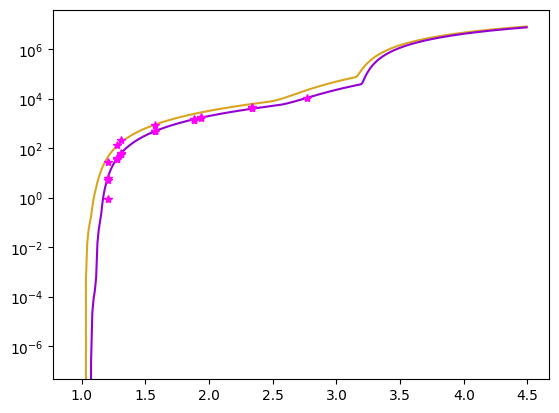

In [5]:
# plt.semilogy(hc/ephoton, 1e7/alphaCoeff, label='Total absorption')
plt.semilogy(ephoton, alphaCoeff, label='Total absorption')

plt.semilogy(ephoton, alphaLN2, label=f'Total absorption, T = {Tln2}K')

plt.semilogy(dfRT[colEph], dfRT[colSigma] * rho_si, marker = "*", linestyle = "None", label='Experimental data')

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../o

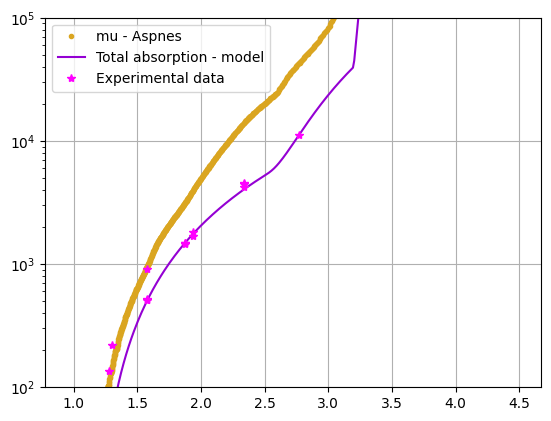

In [6]:
## comparing to n, k data

dh = OpticsData()
wlens = np.arange(hc/max(ephoton), hc/1.2, 1)
photon = PhotonInfo(wlen = wlens)

plt.semilogy(hc/photon.wlen, 1e7 * photon.muSi, marker = ".", linestyle="None", label='mu - Aspnes')

plt.semilogy(ephoton, alphaLN2, label='Total absorption - model')

plt.semilogy(dfRT[colEph], dfRT[colSigma] * rho_si, marker = "*", linestyle = "None", label='Experimental data')

# plt.plot(hc/ephoton, alphaCoeff, label='Total absorption')
# plt.plot(dh.wlen, dh.k, label='k')

# plt.xlim(250, 1200)
plt.ylim(100, 1e5)
plt.legend()
plt.grid()

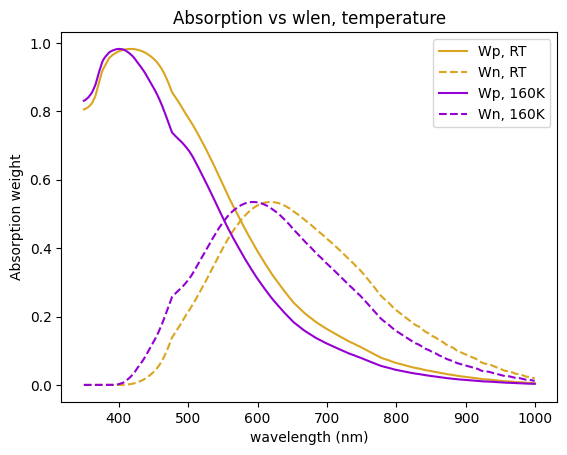

In [22]:
wlens = np.arange(350, 1000, 1)

# photonStandard = PhotonInfo(wlen = wlens)

photonStandard = PhotonInfo(wlen = wlens, materialTemp = 300)

photonCold = PhotonInfo(wlen = wlens, materialTemp = 160)

dh_Franta = OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "Franta_data", "Franta-150K.txt"))
phFranta = PhotonInfo(wlen = wlens, theta_1=0, dataHelper=dh_Franta)
WpFranta = pn.calcWp(phFranta)
WnFranta = pn.calcWn(phFranta)

pn = PNJunction(tOxide = 17, dp_star = 2, Xpn=800, dw_star=4e3, pe = 1.0, ph = 0.4)

ms.ResetColorCycle()
col = ms.GetNextColor()
plt.plot(wlens, pn.calcWp(photonStandard), color = col, label='Wp, RT')
plt.plot(wlens, pn.calcWn(photonStandard), color = col, linestyle="--", label='Wn, RT')

col = ms.GetNextColor()
plt.plot(wlens, pn.calcWp(photonCold), color = col, label='Wp, 160K')
plt.plot(wlens, pn.calcWn(photonCold), color = col, linestyle="--", label='Wn, 160K')

# col = ms.GetNextColor()
# plt.plot(wlens, WpFranta, color = col, label='Wp, Franta')
# plt.plot(wlens, WnFranta, linestyle="--", color = col, label='Wn, Franta')


plt.xlabel("wavelength (nm)")
plt.ylabel("Absorption weight")
plt.title("Absorption vs wlen, temperature")

plt.legend()
plt.show()
# plt.grid()

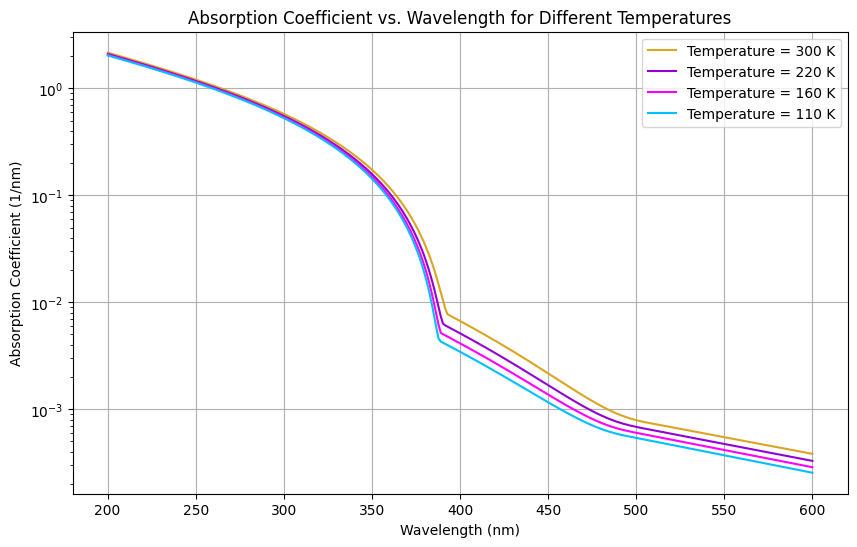

In [8]:
## plot alpha for different temperatures over full wlen range
plt.figure(figsize=(10, 6))

# plt.xlim(300, 800)
ePhotonZoom = np.arange(hc/600, hc/200, 0.01)

plotTemps = [300, 220, 160, 110]
for temp in plotTemps:
    alpha_temp, *_ = TC.alpha(ePhotonZoom, temp, includeDirect=1, fixDirectBandGap=False)
    alpha_nm = alpha_temp * 1e-7
    plt.semilogy(hc/ePhotonZoom, alpha_nm, label=f'Temperature = {temp} K')


plt.xlabel('Wavelength (nm)')
plt.ylabel('Absorption Coefficient (1/nm)')
plt.title('Absorption Coefficient vs. Wavelength for Different Temperatures')
plt.legend()
plt.grid(True)
plt.show()

0.9314966812038674


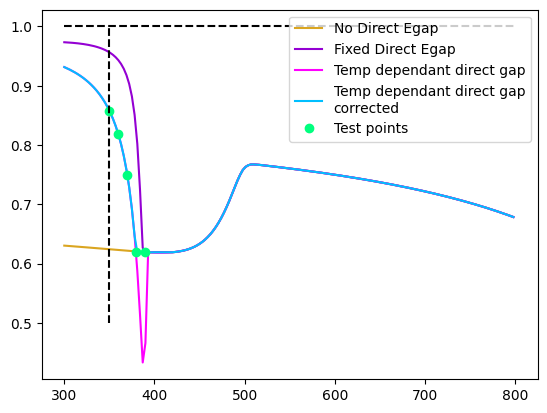

In [9]:
wlens = np.arange(300, 800, 3)

plt.plot(wlens, TC.RelativeAlphaChange(300, 160, wlens, 0), label='No Direct Egap')
plt.plot(wlens, TC.RelativeAlphaChange(300, 160, wlens, 1, 1), label='Fixed Direct Egap')
plt.plot(wlens, TC.RelativeAlphaChange(300, 160, wlens, 1, 0, 0), label='Temp dependant direct gap')
plt.plot(wlens, TC.RelativeAlphaChange(300, 160, wlens, 1, 0, 1), label='Temp dependant direct gap\ncorrected')


testWlens = np.array([349.970, 360.007, 369.988, 379.972, 389.958])
plt.plot(testWlens, TC.RelativeAlphaChange(300, 160, testWlens, 1, 0, 1), marker='o', linestyle='None', label='Test points')
print(max(TC.RelativeAlphaChange(300, 160, wlens, 1, 0)))

plt.legend()
plt.hlines(1, 300, 800, linestyle='--', color='black')
plt.vlines([350], 0.5, 1., linestyle='--', color='black')

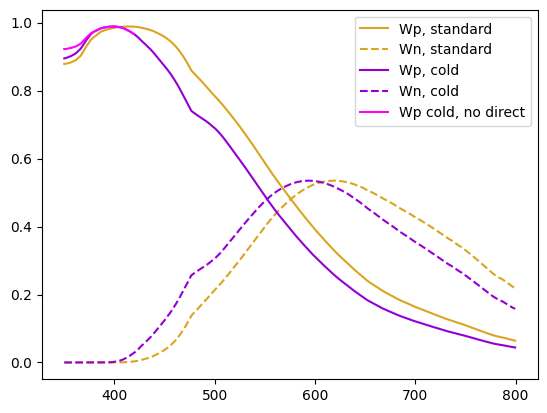

In [10]:
# unlike above, this is the aspnes data (shape) simply scaled by how the DM paper changes
wlens = np.arange(350, 800, 0.5)

photonStandard = PhotonInfo(wlen = wlens)

photonCold = PhotonInfo(wlen = wlens)
photonCold.muSi = photonCold.muSi * TC.RelativeAlphaChange(Tdata=300, Tnew=160, wlen=wlens)

photonNoDirect = PhotonInfo(wlen = wlens)
photonNoDirect.muSi = photonNoDirect.muSi * TC.RelativeAlphaChange(Tdata=300, Tnew=160, wlen=wlens, includeDirect=0)


pn = PNJunction(tOxide = 17, dp_star = 1.2, Xpn=800, dw_star=4e3, pe = 1.0, ph = 0.4)
ms.ResetColorCycle()
col = ms.GetNextColor()
plt.plot(wlens, pn.calcWp(photonStandard), color = col, label='Wp, standard')
plt.plot(wlens, pn.calcWn(photonStandard), color = col, linestyle="--", label='Wn, standard')

col = ms.GetNextColor()
plt.plot(wlens, pn.calcWp(photonCold), color = col, label='Wp, cold')
plt.plot(wlens, pn.calcWn(photonCold), color = col, linestyle="--", label='Wn, cold')

col = ms.GetNextColor()
plt.plot(wlens[wlens < 420], pn.calcWp(photonNoDirect)[wlens < 420], color = col, label='Wp cold, no direct')
# plt.plot(wlens, pn.calcWn(photonNoDirect), color = col, linestyle="--", label='Wn, no direct')

plt.legend()
plt.show()
# plt.grid()

## the cold values, with no direct abs, actually increase Wp at low wavelength because there is decreased absorption with lower
# temperature, and it has a greater effect when the less temp dependant direct bandgap term is ignored

---
Extracting k from alpha

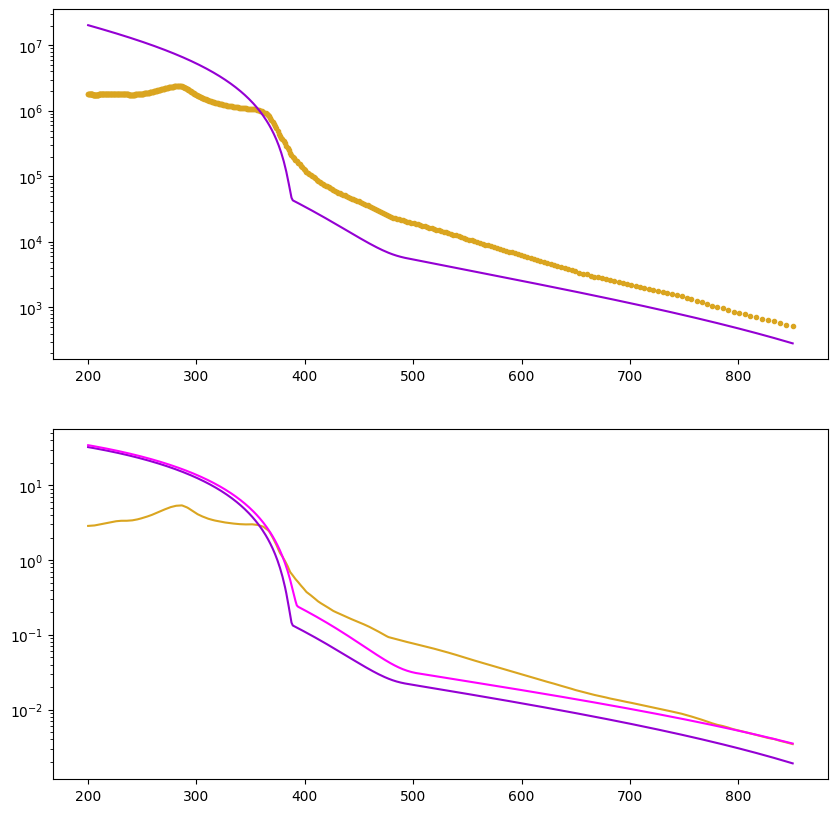

In [11]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10))

def kFromAlpha(alpha, ePhoton):
    wlen = hc/ePhoton
    return alpha * wlen / (4*np.pi)

ePhoton = np.arange(hc/850, hc/200, 0.01)
alpha1, *_ = TC.alpha(ePhoton, 110, includeDirect=True)

alpha2, *_ = TC.alpha(ePhoton, 300, includeDirect=True)

photon = PhotonInfo(wlen = hc/ePhoton)

ax1.semilogy(photon.wlen, 1e7 * photon.muSi, marker = ".", linestyle="None", label='mu - Aspnes')
ax1.semilogy(hc/ePhoton, alpha1, label='110K')

ax2.semilogy(hc/ePhoton, kFromAlpha(photon.muSi, ePhoton), label='110K')
ax2.semilogy(hc/ePhoton, kFromAlpha(1e-7 * alpha1, ePhoton), label='110K dm paper')
ax2.semilogy(hc/ePhoton, kFromAlpha(1e-7 * alpha2, ePhoton), label='300K dm paper')

---
## Maybe i am using the wrong equation with the power for the direct bandgap



$$\alpha = \frac{(E_p - E_g)^{p}}{E_g^m} \propto \frac{k}{\lambda} = \frac{k}{hc}E_p$$

$$ k = \frac{(E_p - E_g)^p}{E_p^m}\frac{hc}{E_p}$$

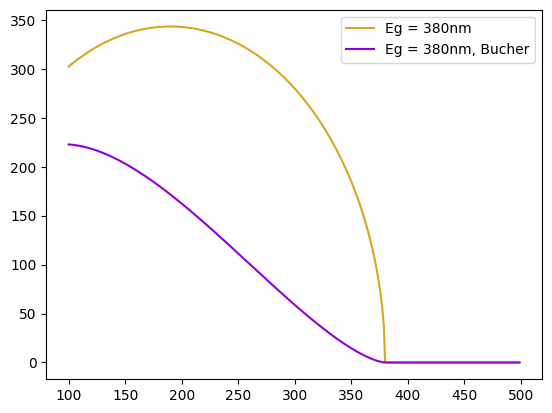

In [12]:
def kToAlpha(Ep, Eg, p, m):
    
    return (Ep - Eg)**p /(Ep**m) * hc/Ep
    
    
# this ignores prefactors and proportionality constants
def kFromParamtrization(wlen, Eg, power=0.5, power2 = 1):
    Ep = hc/wlen
    return np.piecewise(Ep, [Ep >= Eg, Ep < Eg], [lambda x: kToAlpha(x, Eg, power, power2), 0])

    
# def kFromPar_lorentz(wlen, Eg, gamma, p1, p2):
    
#     # mask = hc/wlen >= Eg
#     mask = hc/wlen >= Eg
#     Eph = hc/wlen[mask]
#     result = np.zeros_like(wlen)
    
#     first = (Eph - Eg)**p1/(Eph**p2)
#     second = gamma/((Eph - Eg)**2 + gamma**2)
    
#     result[mask] = first * second
#     return result
    

wlen = np.arange(100, 500, 1, dtype=float)
Eg = hc/380

plt.plot(wlen, kFromParamtrization(wlen, Eg, 0.5, 0), label='Eg = 380nm')

plt.plot(wlen, kFromParamtrization(wlen, Eg, 1.5, 1), label='Eg = 380nm, Bucher')

# plt.plot(wlen, 1e-2*kFromParamtrization(wlen, Eg, 0.5, 2), label='Eg = 380nm')

plt.legend()

# plt.plot(wlen, kFromPar_lorentz(wlen, Eg, 0.1, 0.5, 1), label='Eg = 380nm')